1. Import libraries and load the dataset

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Load CSV

In [21]:
# For Google Colab, uncomment these two lines to upload the CSV:
# from google.colab import files
# uploaded = files.upload()
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("Social_Media_Engagement_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving Social_Media_Engagement_Dataset.csv to Social_Media_Engagement_Dataset.csv
Dataset loaded successfully!
Dataset shape: (12000, 28)


,post_id,timestamp,day_of_week,platform,user_id,location,language,text_content,hashtags,mentions,...,comments_count,impressions,engagement_rate,brand_name,product_name,campaign_name,campaign_phase,user_past_sentiment_avg,user_engagement_growth,buzz_change_rate
0,kcqbs6hxybia,2024-12-09 11:26:15,Monday,Instagram,user_52nwb0a6,"Melbourne, Australia",pt,Just tried the Chromebook from Google. Best pu...,#Food,NaN,...,701,18991,0.19319,Google,Chromebook,BlackFriday,Launch,0.0953,-0.3672,19.1
1,vkmervg4ioos,2024-07-28 19:59:26,Sunday,Twitter,user_ucryct98,"Tokyo, Japan",ru,Just saw an ad for Microsoft Surface Laptop du...,"#MustHave, #Food","@CustomerService, @BrandCEO",...,359,52764,0.05086,Microsoft,Surface Laptop,PowerRelease,Post-Launch,0.1369,-0.4510,-42.6
2,memhx4o1x6yu,2024-11-23 14:00:12,Saturday,Reddit,user_7rrev126,"Beijing, China",ru,What's your opinion about Nike's Epic React? ...,"#Promo, #Food, #Trending",NaN,...,643,8887,0.45425,Nike,Epic React,BlackFriday,Post-Launch,0.2855,-0.4112,17.4
3,bhyo6piijqt9,2024-09-16 04:35:25,Monday,YouTube,user_4mxuq0ax,"Lagos, Nigeria",en,Bummed out with my new Diet Pepsi from Pepsi! ...,"#Reviews, #Sustainable","@StyleGuide, @BrandSupport",...,743,6696,0.42293,Pepsi,Diet Pepsi,LaunchWave,Launch,-0.2094,-0.0167,-5.5
4,c9dkiomowakt,2024-09-05 21:03:01,Thursday,Twitter,user_l1vpox2k,"Berlin, Germany",hi,Just tried the Corolla from Toyota. Absolutely...,"#Health, #Travel","@BrandSupport, @InfluencerName",...,703,47315,0.08773,Toyota,Corolla,LocalTouchpoints,Launch,0.6867,0.0807,38.8


2. Inspect the dataset

In [22]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['post_id', 'timestamp', 'day_of_week', 'platform', 'user_id', 'location', 'language', 'text_content', 'hashtags', 'mentions', 'keywords', 'topic_category', 'sentiment_score', 'sentiment_label', 'emotion_type', 'toxicity_score', 'likes_count', 'shares_count', 'comments_count', 'impressions', 'engagement_rate', 'brand_name', 'product_name', 'campaign_name', 'campaign_phase', 'user_past_sentiment_avg', 'user_engagement_growth', 'buzz_change_rate']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   post_id                  12000 non-null  object 
 1   timestamp                12000 non-null  object 
 2   day_of_week              12000 non-null  object 
 3   platform                 12000 non-null  object 
 4   user_id                  12000 non-null  object 
 5   location              

,sentiment_score,toxicity_score,likes_count,shares_count,comments_count,impressions,engagement_rate,user_past_sentiment_avg,user_engagement_growth,buzz_change_rate
count,12000.000000,12000.000000,12000.00000,12000.000000,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,0.000553,0.503868,2490.72025,1007.167167,504.34575,49811.338500,0.278137,0.001472,0.000998,0.729692
std,0.583563,0.288198,1441.53253,575.072282,288.68416,28930.289451,1.149206,0.576627,0.289940,57.787219
min,-0.999800,0.000000,0.00000,0.000000,0.00000,130.000000,0.001880,-0.999600,-0.499900,-99.900000
25%,-0.503200,0.251400,1236.00000,510.000000,253.00000,24716.500000,0.049100,-0.495975,-0.248400,-48.700000
50%,-0.006200,0.505950,2496.00000,1018.000000,503.00000,49674.000000,0.080605,0.001950,0.002800,0.900000
75%,0.513525,0.756200,3723.25000,1501.000000,755.00000,74815.000000,0.163123,0.501725,0.250700,50.100000
max,0.999900,0.999900,5000.00000,2000.000000,1000.00000,99997.000000,32.211710,0.999400,0.499900,99.900000



Missing values:
post_id                       0
timestamp                     0
day_of_week                   0
platform                      0
user_id                       0
location                      0
language                      0
text_content                  0
hashtags                      0
mentions                   3941
keywords                      0
topic_category                0
sentiment_score               0
sentiment_label               0
emotion_type                  0
toxicity_score                0
likes_count                   0
shares_count                  0
comments_count                0
impressions                   0
engagement_rate               0
brand_name                    0
product_name                  0
campaign_name                 0
campaign_phase                0
user_past_sentiment_avg       0
user_engagement_growth        0
buzz_change_rate              0
dtype: int64

Duplicate rows: 0


Q1 — What are the average, minimum, and maximum likes for each social media platform?

In [23]:
platforms = df["platform"].unique()

for platform in platforms:
    likes = df.loc[df["platform"] == platform, "likes_count"].to_numpy()
    print("\nPlatform:", platform)
    print("Average likes:", round(np.mean(likes), 2))
    print("Minimum likes:", np.min(likes))
    print("Maximum likes:", np.max(likes))


Platform: Instagram
Average likes: 2506.01
Minimum likes: 1
Maximum likes: 5000

Platform: Twitter
Average likes: 2445.19
Minimum likes: 1
Maximum likes: 4999

Platform: Reddit
Average likes: 2497.91
Minimum likes: 1
Maximum likes: 5000

Platform: YouTube
Average likes: 2481.82
Minimum likes: 4
Maximum likes: 5000

Platform: Facebook
Average likes: 2522.87
Minimum likes: 0
Maximum likes: 5000


NumPy: arrays, indexing, arithmetic, and sampling

In [24]:
likes_arr = df["likes_count"].to_numpy()
print("Array shape:", likes_arr.shape)
print("First 5 likes:", likes_arr[:5])
print("Last 5 likes:", likes_arr[-5:])
print("Likes above 1000 (first 5):", likes_arr[likes_arr > 1000][:5])

shares_arr = df["shares_count"].to_numpy()
comments_arr = df["comments_count"].to_numpy()
total_interactions = likes_arr + shares_arr + comments_arr
print("Total interactions for first 5 posts:", total_interactions[:5])

matrix = df[["likes_count", "shares_count", "comments_count", "impressions"]].to_numpy()
print("Matrix shape:", matrix.shape)
print("Transposed shape:", matrix.T.shape)
print("Column means:", matrix.mean(axis=0).round(2))

rng = np.random.default_rng(42)
sample = rng.choice(likes_arr, size=100, replace=False)
print("Sample mean likes:", round(sample.mean(), 2))
print("Full dataset mean likes:", round(likes_arr.mean(), 2))

Array shape: (12000,)
First 5 likes: [1264  522 2689 1827 2005]
Last 5 likes: [3878 1747 2628 1943  236]
Likes above 1000 (first 5): [1264 2689 1827 2005 3828]
Total interactions for first 5 posts: [3669 2684 4037 2832 4151]
Matrix shape: (12000, 4)
Transposed shape: (4, 12000)
Column means: [ 2490.72  1007.17   504.35 49811.34]
Sample mean likes: 2515.78
Full dataset mean likes: 2490.72


Q2 — Which platforms and brands receive the most engagement, and how does engagement differ by sentiment?
A. Platform performance

In [25]:
platform_analysis = df.groupby("platform").agg(
    Total_Likes=("likes_count", "sum"),
    Total_Shares=("shares_count", "sum"),
    Total_Comments=("comments_count", "sum"),
    Average_Engagement_Rate=("engagement_rate", "mean"),
    Total_Impressions=("impressions", "sum")
).round(2)

platform_analysis = platform_analysis.sort_values("Total_Likes", ascending=False)
display(platform_analysis)

print("Platform with most likes:", platform_analysis["Total_Likes"].idxmax())
print("Platform with highest average engagement rate:",
      platform_analysis["Average_Engagement_Rate"].idxmax())

,Total_Likes,Total_Shares,Total_Comments,Average_Engagement_Rate,Total_Impressions
platform,,,,,
Facebook,6133107,2388476,1210935,0.29,121027500
YouTube,6045720,2479543,1235523,0.28,122988419
Reddit,5925053,2364548,1216551,0.28,116488833
Instagram,5901643,2454870,1172787,0.29,117664271
Twitter,5883120,2398569,1216353,0.26,119567039


Platform with most likes: Facebook
Platform with highest average engagement rate: Facebook


B. Engagement by sentiment

In [26]:
sentiment_analysis = df.groupby("sentiment_label").agg(
    Posts=("post_id", "count"),
    Average_Likes=("likes_count", "mean"),
    Average_Shares=("shares_count", "mean"),
    Average_Comments=("comments_count", "mean"),
    Average_Engagement_Rate=("engagement_rate", "mean")
).round(2)

display(sentiment_analysis)

,Posts,Average_Likes,Average_Shares,Average_Comments,Average_Engagement_Rate
sentiment_label,,,,,
Negative,4854,2514.73,1007.26,502.29,0.28
Neutral,2307,2471.07,998.41,502.77,0.31
Positive,4839,2476.00,1011.25,507.16,0.26


C. Engagement by brand

In [27]:
brand_analysis = df.groupby("brand_name").agg(
    Total_Likes=("likes_count", "sum"),
    Total_Shares=("shares_count", "sum"),
    Total_Comments=("comments_count", "sum"),
    Average_Engagement_Rate=("engagement_rate", "mean"),
    Number_of_Posts=("post_id", "count")
).round(2).sort_values("Total_Likes", ascending=False)

display(brand_analysis)
print("Brand with most likes:", brand_analysis["Total_Likes"].idxmax())

,Total_Likes,Total_Shares,Total_Comments,Average_Engagement_Rate,Number_of_Posts
brand_name,,,,,
Samsung,3073984,1245855,620770,0.28,1216
Adidas,3069471,1239344,620083,0.30,1229
Microsoft,3025517,1214531,626471,0.34,1239
Google,3012497,1169502,618881,0.26,1216
Pepsi,2989071,1202583,598861,0.24,1199
Apple,2974167,1234586,601390,0.27,1192
Amazon,2968543,1169086,572006,0.28,1143
Nike,2953217,1239978,623839,0.29,1219
Coca-Cola,2932666,1174053,584769,0.23,1173


Brand with most likes: Samsung


Q3 — Are there missing values or duplicate records, and how are they handled?

In [28]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Fill missing numeric values with each column's median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing text/category values with "Unknown"
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

print("Dataset shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (12000, 28)
Total missing values: 0
Duplicate rows: 0


Categorizing values, hierarchical indexing, and reshaping

In [29]:
# Categorize engagement rate into three groups using the dataset's own cut points
df["Engagement_Category"] = pd.cut(
    df["engagement_rate"],
    bins=[-np.inf, 0.05, 0.15, np.inf],
    labels=["Low", "Medium", "High"]
)

display(df[["engagement_rate", "Engagement_Category"]].head())

# Hierarchical indexing
multi_index = df.set_index(["platform", "sentiment_label"])
display(multi_index[["likes_count", "engagement_rate"]].head())

# Reshape a small sample from wide to long format
reshaped = pd.melt(
    df.head(5),
    id_vars=["platform"],
    value_vars=["likes_count", "shares_count", "comments_count"],
    var_name="Measure",
    value_name="Value"
)
display(reshaped)

,engagement_rate,Engagement_Category
0,0.19319,High
1,0.05086,Medium
2,0.45425,High
3,0.42293,High
4,0.08773,Medium


,,likes_count,engagement_rate
platform,sentiment_label,,
Instagram,Positive,1264,0.19319
Twitter,Negative,522,0.05086
Reddit,Negative,2689,0.45425
YouTube,Negative,1827,0.42293
Twitter,Positive,2005,0.08773


,platform,Measure,Value
0,Instagram,likes_count,1264
1,Twitter,likes_count,522
2,Reddit,likes_count,2689
3,YouTube,likes_count,1827
4,Twitter,likes_count,2005
5,Instagram,shares_count,1704
6,Twitter,shares_count,1803
7,Reddit,shares_count,705
8,YouTube,shares_count,262
9,Twitter,shares_count,1443


Merge brand engagement with brand post counts

In [30]:
brand_engagement = df.groupby("brand_name", as_index=False).agg(
    Average_Engagement=("engagement_rate", "mean"),
    Total_Likes=("likes_count", "sum"),
    Total_Shares=("shares_count", "sum")
)

brand_posts = df.groupby("brand_name", as_index=False).agg(
    Number_of_Posts=("post_id", "count"),
    Average_Sentiment=("sentiment_score", "mean")
)

merged_data = pd.merge(brand_engagement, brand_posts, on="brand_name")
merged_data = merged_data.round(3)
display(merged_data)

,brand_name,Average_Engagement,Total_Likes,Total_Shares,Number_of_Posts,Average_Sentiment
0,Adidas,0.298,3069471,1239344,1229,-0.020
1,Amazon,0.285,2968543,1169086,1143,-0.011
2,Apple,0.273,2974167,1234586,1192,-0.002
3,Coca-Cola,0.228,2932666,1174053,1173,0.028
4,Google,0.257,3012497,1169502,1216,0.017
5,Microsoft,0.341,3025517,1214531,1239,0.008
6,Nike,0.287,2953217,1239978,1219,-0.011
7,Pepsi,0.238,2989071,1202583,1199,-0.003
8,Samsung,0.276,3073984,1245855,1216,-0.012
9,Toyota,0.296,2889510,1196488,1174,0.012


4. Correlation analysis

In [31]:
numeric_cols = [
    "sentiment_score",
    "toxicity_score",
    "likes_count",
    "shares_count",
    "comments_count",
    "impressions",
    "engagement_rate",
    "user_past_sentiment_avg",
    "user_engagement_growth",
    "buzz_change_rate"
]

correlation_matrix = df[numeric_cols].corr()
print("Correlation matrix:")
display(correlation_matrix.round(2))

Correlation matrix:


,sentiment_score,toxicity_score,likes_count,shares_count,comments_count,impressions,engagement_rate,user_past_sentiment_avg,user_engagement_growth,buzz_change_rate
sentiment_score,1.00,0.01,-0.02,0.00,0.01,0.00,-0.01,0.01,-0.01,-0.01
toxicity_score,0.01,1.00,-0.01,0.01,-0.02,0.01,-0.02,-0.01,-0.00,-0.00
likes_count,-0.02,-0.01,1.00,0.00,0.01,0.00,0.08,0.00,0.01,0.01
shares_count,0.00,0.01,0.00,1.00,0.02,-0.01,0.04,0.01,-0.01,-0.01
comments_count,0.01,-0.02,0.01,0.02,1.00,-0.01,0.01,-0.02,0.01,0.01
impressions,0.00,0.01,0.00,-0.01,-0.01,1.00,-0.30,0.01,0.01,0.00
engagement_rate,-0.01,-0.02,0.08,0.04,0.01,-0.30,1.00,-0.02,-0.01,-0.01
user_past_sentiment_avg,0.01,-0.01,0.00,0.01,-0.02,0.01,-0.02,1.00,-0.00,0.01
user_engagement_growth,-0.01,-0.00,0.01,-0.01,0.01,0.01,-0.01,-0.00,1.00,0.00
buzz_change_rate,-0.01,-0.00,0.01,-0.01,0.01,0.00,-0.01,0.01,0.00,1.00


Heatmap of correlations

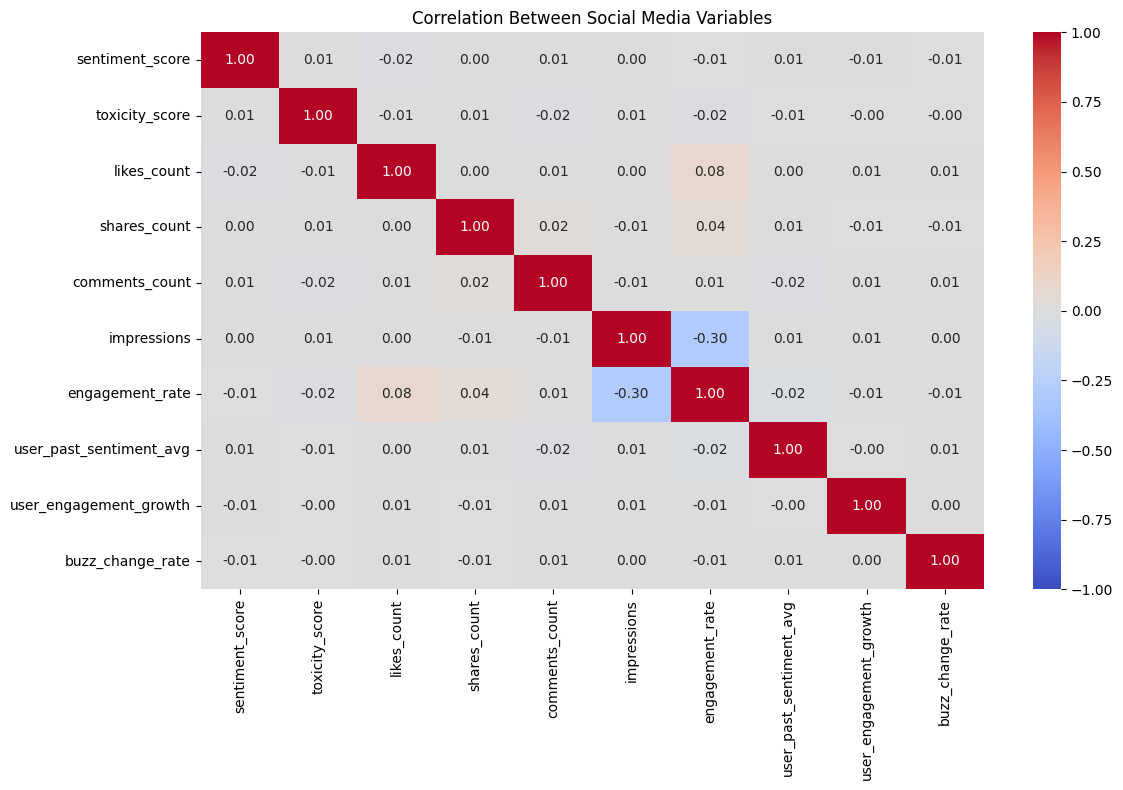

In [32]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Social Media Variables")
plt.tight_layout()
plt.show()

Q4 — How does engagement vary by platform and date, and what relationships exist among numerical variables?

A. Engagement by platform and campaign phase

In [33]:
platform_campaign = df.groupby(["platform", "campaign_phase"]).agg(
    Total_Likes=("likes_count", "sum"),
    Total_Shares=("shares_count", "sum"),
    Total_Comments=("comments_count", "sum"),
    Average_Engagement_Rate=("engagement_rate", "mean")
).round(3)

display(platform_campaign)
print("Platform with highest total likes:",
      df.groupby("platform")["likes_count"].sum().idxmax())

Total_Likes  Total_Shares  Total_Comments  \
platform  campaign_phase                                              
Facebook  Launch              2002022        817481          402055   
          Post-Launch         2006605        736885          396019   
          Pre-Launch          2124480        834110          412861   
Instagram Launch              1954118        810394          380753   
          Post-Launch         2089990        843855          399394   
          Pre-Launch          1857535        800621          392640   
Reddit    Launch              2050062        814793          419516   
          Post-Launch         1950654        770494          400730   
          Pre-Launch          1924337        779261          396305   
Twitter   Launch              2085657        842679          418704   
          Post-Launch         1932113        789633          393966   
          Pre-Launch          1865350        766257          403683   
YouTube   Launch              1955568        819010          403816   
          Post-Launch         2052923        837870          415189   
          Pre-Launch          2037229        822663          416518   

                          Average_Engagement_Rate  
platform  campaign_phase                           
Facebook  Launch                            0.278  
          Post-Launch                       0.307  
          Pre-Launch                        0.275  
Instagram Launch                            0.235  
          Post-Launch                       0.345  
          Pre-Launch                        0.279  
Reddit    Launch                            0.250  
          Post-Launch                       0.221  
          Pre-Launch                        0.366  
Twitter   Launch                            0.313  
          Post-Launch                       0.252  
          Pre-Launch                        0.210  
YouTube   Launch                            0.199  
          Post-Launch                       0.294  
          Pre-Launch                        0.340

Platform with highest total likes: Facebook


B. Daily post and engagement trend

,engagement_rate
date,
2024-05-01,0.132145
2024-05-02,0.210852
2024-05-03,0.206160
2024-05-04,0.544181
2024-05-05,0.202201


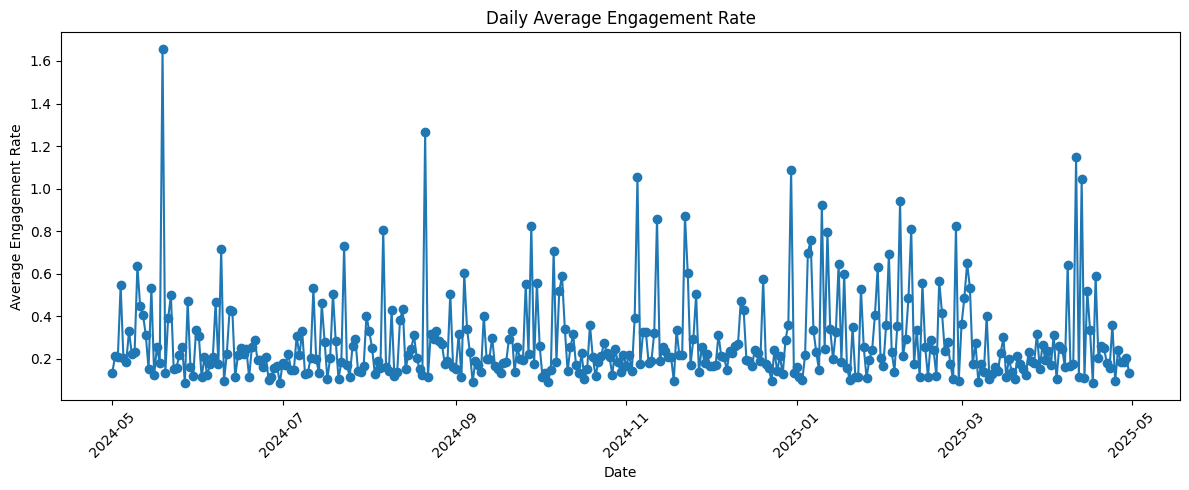

In [34]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
time_df = df.dropna(subset=["timestamp"]).copy()
time_df["date"] = time_df["timestamp"].dt.date

daily_engagement = time_df.groupby("date")["engagement_rate"].mean().sort_index()
daily_posts = time_df.groupby("date")["post_id"].count().sort_index()

display(daily_engagement.head())

plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index, daily_engagement.values, marker="o")
plt.title("Daily Average Engagement Rate")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C. Monthly engagement trend and date filtering

Posts in January 2025:


,platform,engagement_rate,likes_count
timestamp,,,
2025-01-01 00:32:44,Twitter,0.05441,2523
2025-01-01 00:38:29,Reddit,0.08951,120
2025-01-01 00:39:44,Reddit,1.14532,3098
2025-01-01 01:38:15,Facebook,0.03265,148
2025-01-01 03:00:56,Reddit,0.09351,3879


,engagement_rate
timestamp,
2024-05-01,0.295055
2024-06-01,0.225235
2024-07-01,0.246279
2024-08-01,0.282617
2024-09-01,0.270974
2024-10-01,0.235105
2024-11-01,0.326860
2024-12-01,0.258747
2025-01-01,0.330479


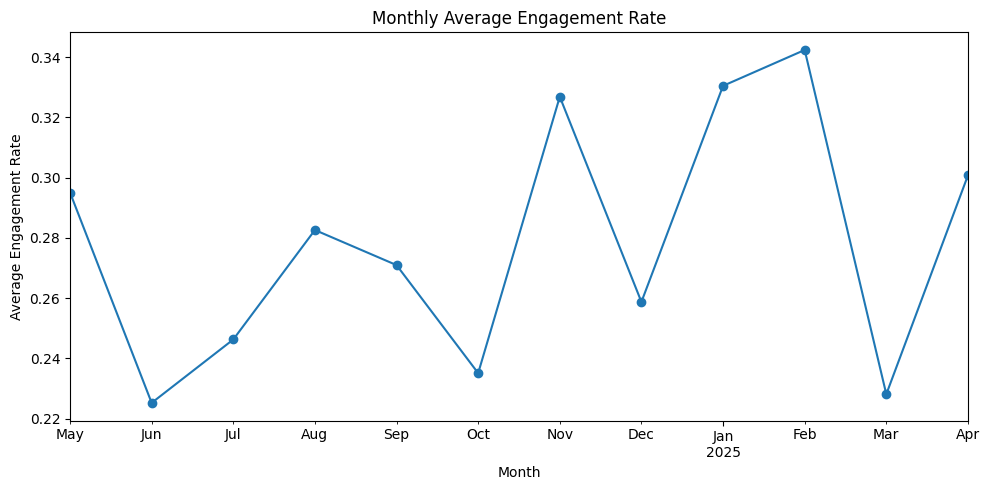

In [35]:
time_data = time_df.set_index("timestamp").sort_index()

print("Posts in January 2025:")
display(time_data.loc["2025-01", ["platform", "engagement_rate", "likes_count"]].head())

monthly_engagement = time_data["engagement_rate"].resample("MS").mean()
display(monthly_engagement)

plt.figure(figsize=(10, 5))
monthly_engagement.plot(marker="o")
plt.title("Monthly Average Engagement Rate")
plt.xlabel("Month")
plt.ylabel("Average Engagement Rate")
plt.tight_layout()
plt.show()

D. Identify the date with the highest average engagement

In [36]:
peak_date = daily_engagement.idxmax()
peak_posts = time_df[time_df["date"] == peak_date]

print("Peak date:", peak_date)
print("Average engagement rate:", round(daily_engagement.max(), 4))
print("Number of posts:", len(peak_posts))
print("Total likes:", peak_posts["likes_count"].sum())
print("Total shares:", peak_posts["shares_count"].sum())
print("\nPosts by platform on the peak date:")
display(peak_posts.groupby("platform")["post_id"].count().sort_values(ascending=False))

Peak date: 2024-05-19
Average engagement rate: 1.6561
Number of posts: 18
Total likes: 45343
Total shares: 15714

Posts by platform on the peak date:


,post_id
platform,
Twitter,7
Reddit,5
YouTube,3
Instagram,2
Facebook,1


Q5 — What do bar plots, scatter plots, pie charts, line plots, and heatmaps reveal?

A. Total likes by platform

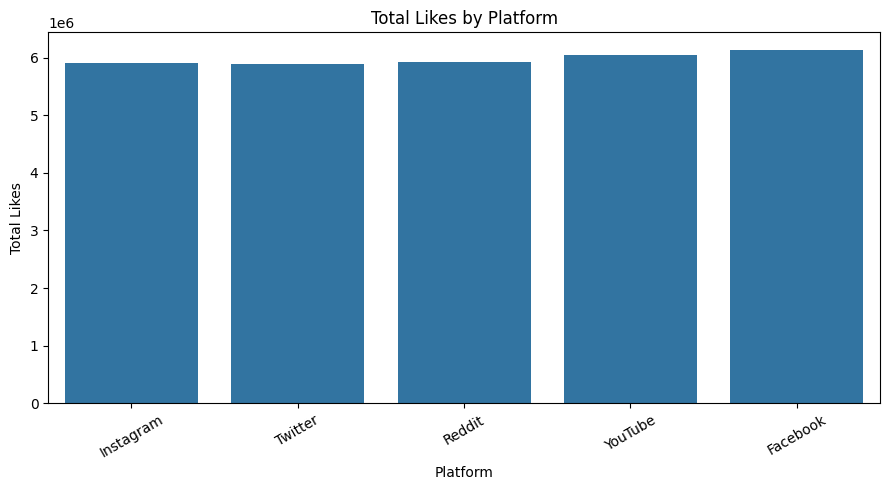

In [37]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="platform", y="likes_count", estimator=sum, errorbar=None)
plt.title("Total Likes by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Likes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

B. Total comments by platform

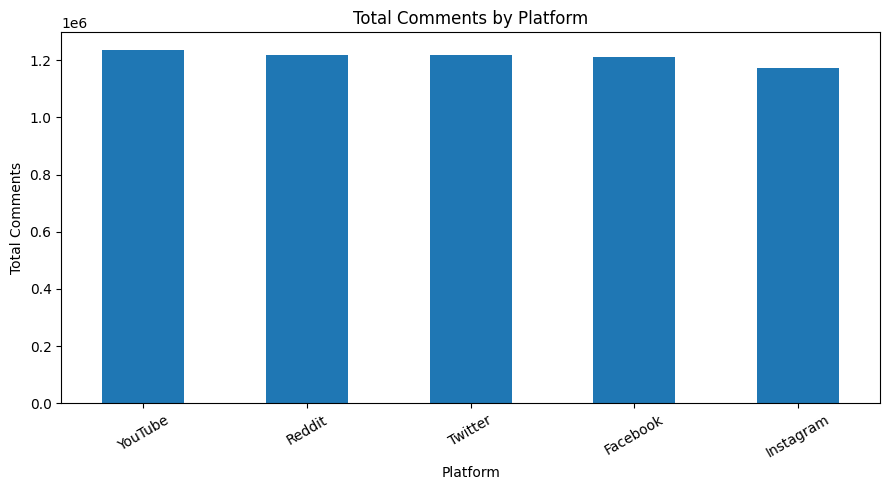

In [38]:
comment_data = df.groupby("platform")["comments_count"].sum().sort_values(ascending=False)
comment_data.plot(kind="bar", figsize=(9, 5))
plt.title("Total Comments by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Comments")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

C. Heatmap of average engagement by platform and sentiment

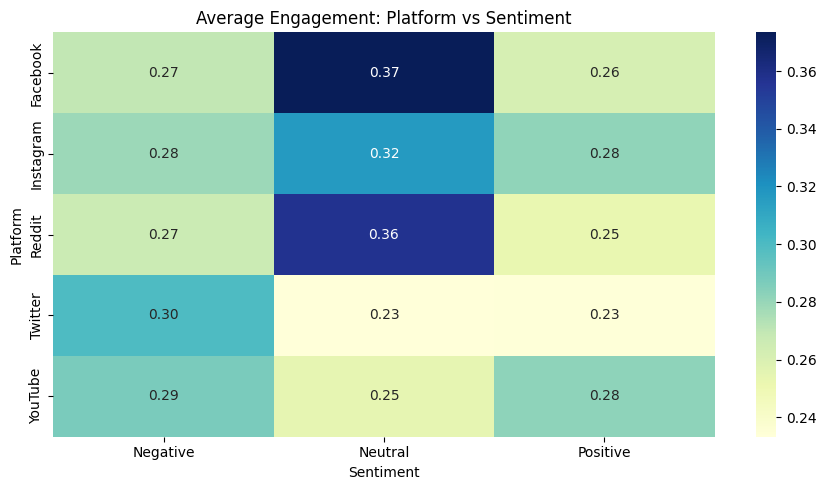

In [39]:
engagement_pivot = df.pivot_table(
    index="platform",
    columns="sentiment_label",
    values="engagement_rate",
    aggfunc="mean",
    fill_value=0
)

plt.figure(figsize=(9, 5))
sns.heatmap(engagement_pivot, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Engagement: Platform vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Platform")
plt.tight_layout()
plt.show()

D. Sentiment label distribution

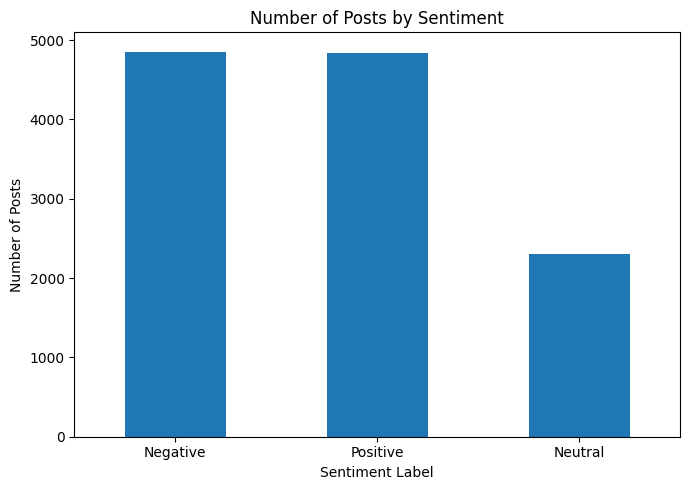

In [40]:
sentiment_counts = df["sentiment_label"].value_counts()
sentiment_counts.plot(kind="bar", figsize=(7, 5))
plt.title("Number of Posts by Sentiment")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

E. Share of posts by platform (pie chart)

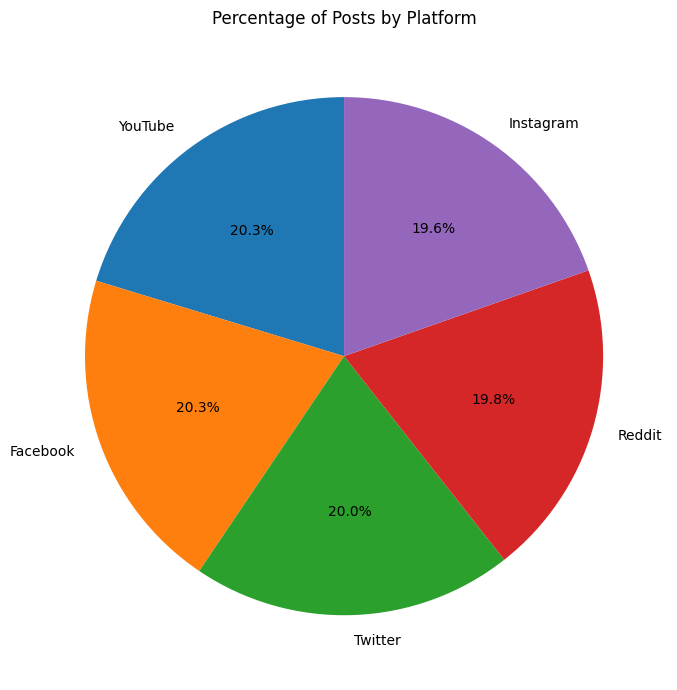

In [41]:
platform_counts = df["platform"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(platform_counts, labels=platform_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Percentage of Posts by Platform")
plt.tight_layout()
plt.show()

F. Total engagement by brand

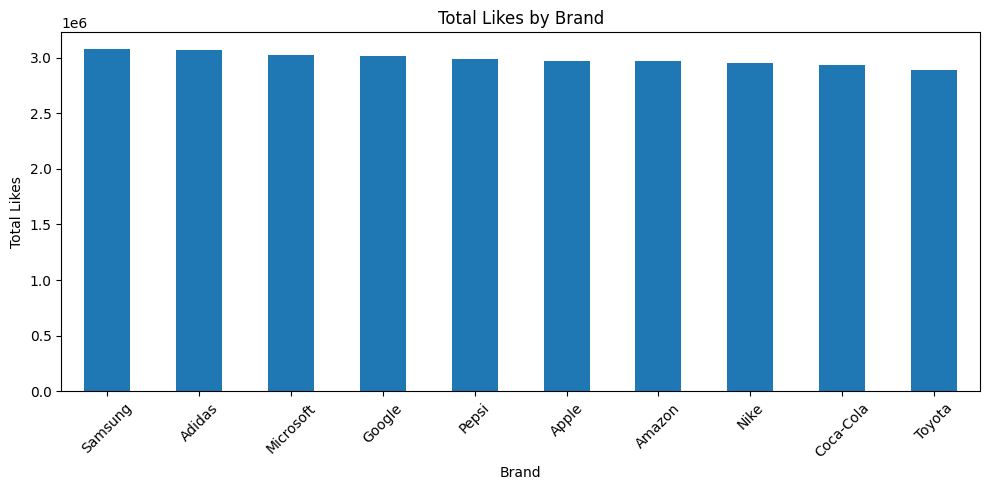

In [42]:
brand_likes = df.groupby("brand_name")["likes_count"].sum().sort_values(ascending=False)
brand_likes.plot(kind="bar", figsize=(10, 5))
plt.title("Total Likes by Brand")
plt.xlabel("Brand")
plt.ylabel("Total Likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

G. Distribution of engagement rate

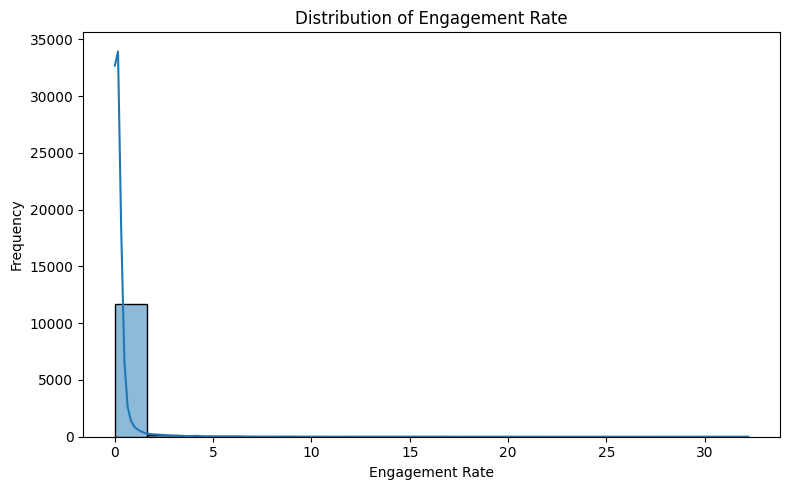

In [43]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="engagement_rate", bins=20, kde=True)
plt.title("Distribution of Engagement Rate")
plt.xlabel("Engagement Rate")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

H. Impressions vs likes scatter plot, colored by platform

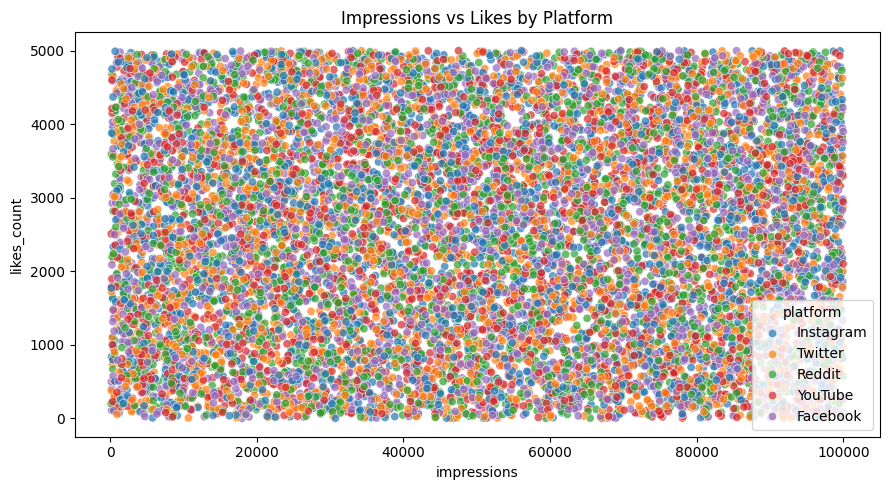

In [44]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="impressions", y="likes_count", hue="platform", alpha=0.7)
plt.title("Impressions vs Likes by Platform")
plt.tight_layout()
plt.show()

I. Sentiment scores by platform

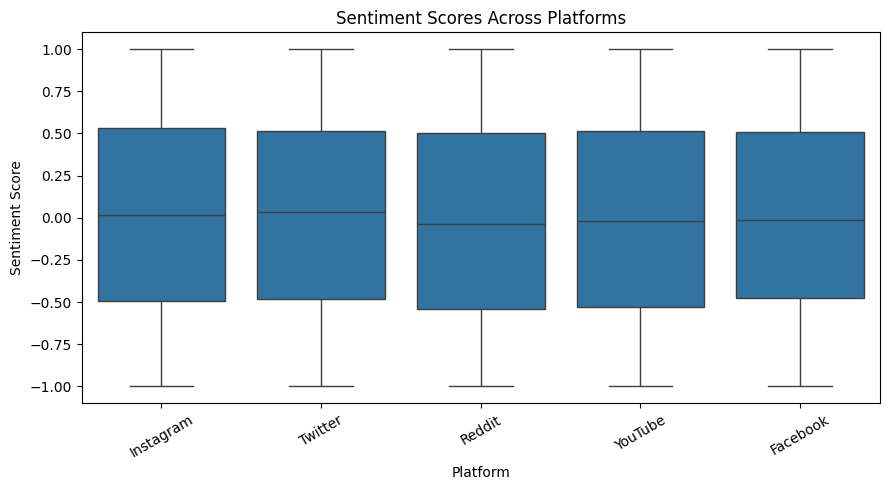

In [45]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="platform", y="sentiment_score")
plt.title("Sentiment Scores Across Platforms")
plt.xlabel("Platform")
plt.ylabel("Sentiment Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

J. Toxicity score by sentiment label

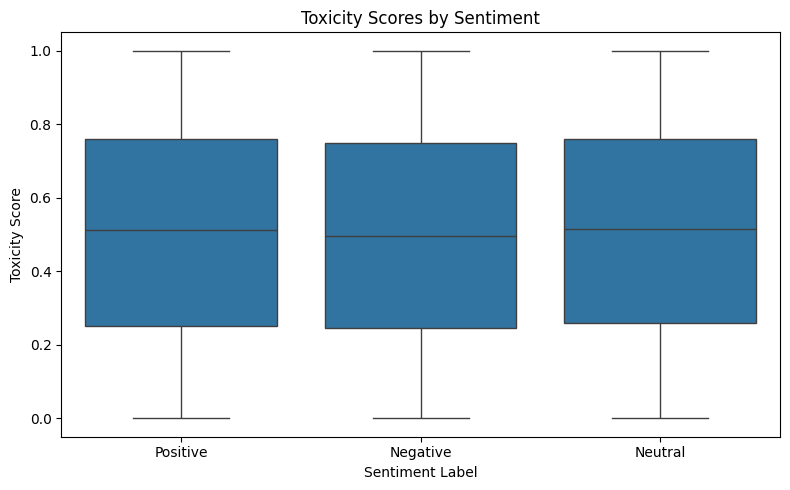

In [46]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sentiment_label", y="toxicity_score")
plt.title("Toxicity Scores by Sentiment")
plt.xlabel("Sentiment Label")
plt.ylabel("Toxicity Score")
plt.tight_layout()
plt.show()